## Charger les images

In [50]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observations_entrainement = pnd.read_csv('data/fashion-mnist_train.csv')

## Affichage de l'image 1

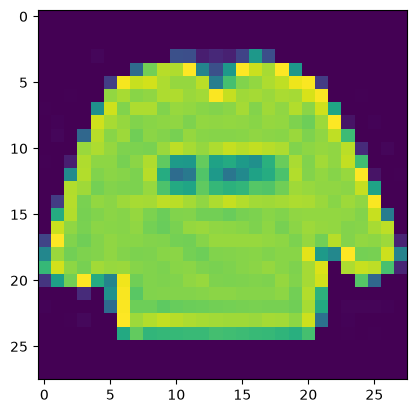

In [51]:
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE, LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

## Préparation des données d'apprentissage

In [52]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))

X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [53]:
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0],
                                          LARGEUR_IMAGE,
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0],
                                    LARGEUR_IMAGE,
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

## Préparation des données de tests

In [54]:
observations_test = pnd.read_csv('data/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

## Une seule couche de convolution

In [55]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

#creation couche par couche
reseauNeurone1Convolution = Sequential()

#Ajout couche entrer
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#ajout couche comportant 32 filtres de taille 3x3
#fonction activation type ReLU
#image d'entrer de 28x28
reseauNeurone1Convolution.add(Conv2D(32,
                                     kernel_size=(3,3),
                                     activation='relu'))

#def fonction de poolong avec une fenetre de 2x2
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2,2)))

#Ajout fonciton ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#transforme en 1 ligne
reseauNeurone1Convolution.add(Flatten())

#reseau neurone de 128n avec fonction ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#reseau neurone de 10n avec fonction softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax')) 

In [56]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

In [64]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9281 - loss: 0.1911 - val_accuracy: 0.9212 - val_loss: 0.2095
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9395 - loss: 0.1639 - val_accuracy: 0.9248 - val_loss: 0.2049
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9454 - loss: 0.1500 - val_accuracy: 0.9252 - val_loss: 0.2049
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9500 - loss: 0.1373 - val_accuracy: 0.9250 - val_loss: 0.2065
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9545 - loss: 0.1260 - val_accuracy: 0.9244 - val_loss: 0.2086
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9576 - loss: 0.1179 - val_accuracy: 0.9242 - val_loss: 0.2105
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9599 - loss: 0.1101 - val_accuracy: 0.9255 - val_loss: 0.2138
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9645 - loss: 0.1009 - val_accuracy: 0.

In [65]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.22015652060508728
Précision: 0.9258000254631042


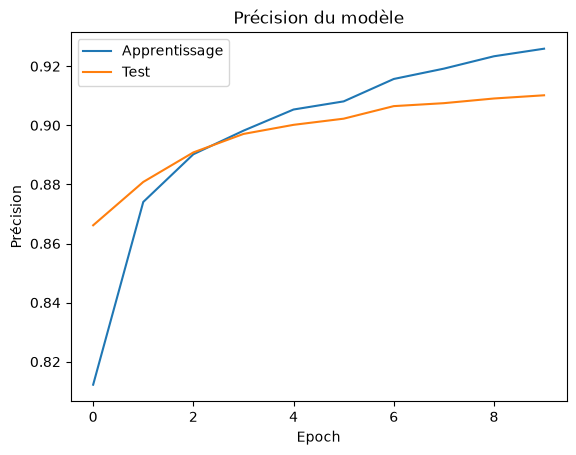

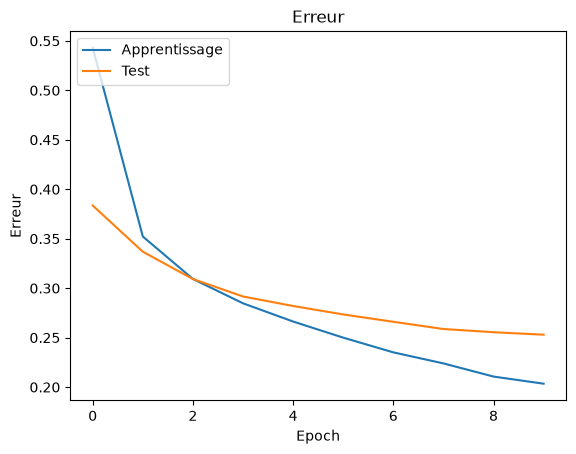

In [59]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

## Augmentation du nombre de donnée

In [60]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

In [66]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8870 - loss: 0.3054 - val_accuracy: 0.8812 - val_loss: 0.3196
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8867 - loss: 0.3184 - val_accuracy: 0.8832 - val_loss: 0.3117
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8926 - loss: 0.2845 - val_accuracy: 0.8859 - val_loss: 0.3104
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8867 - loss: 0.2992 - val_accuracy: 0.8859 - val_loss: 0.3028
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8944 - loss: 0.2798 - val_accuracy: 0.8932 - val_loss: 0.2913
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8789 - loss: 0.3117 - val_accuracy: 0.8932 - val_loss: 0.2936
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8974 - loss: 0.2754 - val_accuracy: 0.8940 - val_loss: 0.2912
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8750 - loss: 0.3767 - val_accuracy

In [68]:
#Sauvegarde du modèle
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)
    
# Serialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !
